# Superstore Sales Performance Analysis

This notebook uses the real Global Superstore dataset included in this project. The amounts are shown as provided; the source covers multiple markets and does not specify one common currency. Each code cell is preceded by a short explanation, and each chart is followed by a data-backed takeaway.

## Load the cleaned data

Import the analysis libraries and read the output produced by `src/clean_data.py`. The path check works both when Jupyter starts in the project folder and when it starts in `notebooks`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

data_path = Path("data/processed/superstore_cleaned.csv")
if not data_path.exists():
    data_path = Path("../data/processed/superstore_cleaned.csv")
if not data_path.exists():
    raise FileNotFoundError("Run src/clean_data.py to create the cleaned CSV first.")

df = pd.read_csv(data_path, parse_dates=["order_date", "ship_date"])
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
print(f"Order dates: {df['order_date'].min():%Y-%m-%d} to {df['order_date'].max():%Y-%m-%d}")
df.head()

Rows: 51,290 | Columns: 32
Order dates: 2011-01-01 to 2014-12-31


,category,city,country,customer_id,customer_name,discount,market,record_count,order_date,order_id,...,state,sub_category,year,market2,weeknum,order_year,order_month,order_month_name,profit_margin,shipping_days
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07,CA-2011-130813,...,California,Paper,2011,North America,2,2011,1,January,0.491116,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21,CA-2011-148614,...,California,Paper,2011,North America,4,2011,1,January,0.489095,5
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05,CA-2011-118962,...,California,Paper,2011,North America,32,2011,8,August,0.468657,4
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05,CA-2011-118962,...,California,Paper,2011,North America,32,2011,8,August,0.479827,4
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29,CA-2011-146969,...,California,Paper,2011,North America,40,2011,9,September,0.518400,4


## 1. Overview

Calculate total sales and profit, count distinct orders and customers, and calculate the overall margin as total profit divided by total sales. A weighted margin is more meaningful here than averaging row-level margins.

In [2]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
overall_margin = total_profit / total_sales

print(f"Total sales: {total_sales:,.0f}")
print(f"Total profit: {total_profit:,.2f}")
print(f"Distinct orders: {total_orders:,}")
print(f"Distinct customers: {total_customers:,}")
print(f"Overall profit margin: {overall_margin:.2%}")

Total sales: 12,642,905
Total profit: 1,467,457.29
Distinct orders: 25,035
Distinct customers: 4,873
Overall profit margin: 11.61%


## 2. Sales and profit trends by month and year

Summarize the data by calendar year and by month. The monthly time series keeps the year in the date so seasonal patterns are not blended across years.

In [3]:
yearly = df.groupby("order_year").agg(
    sales=("sales", "sum"), profit=("profit", "sum")
).sort_index()
monthly = df.groupby(pd.Grouper(key="order_date", freq="MS")).agg(
    sales=("sales", "sum"), profit=("profit", "sum")
).reset_index()
yearly.round(2)

,sales,profit
order_year,,
2011,2259511,248940.81
2012,2677493,307415.28
2013,3405860,406935.23
2014,4300041,504165.97


The next chart shows monthly sales and profit across the full four-year period.

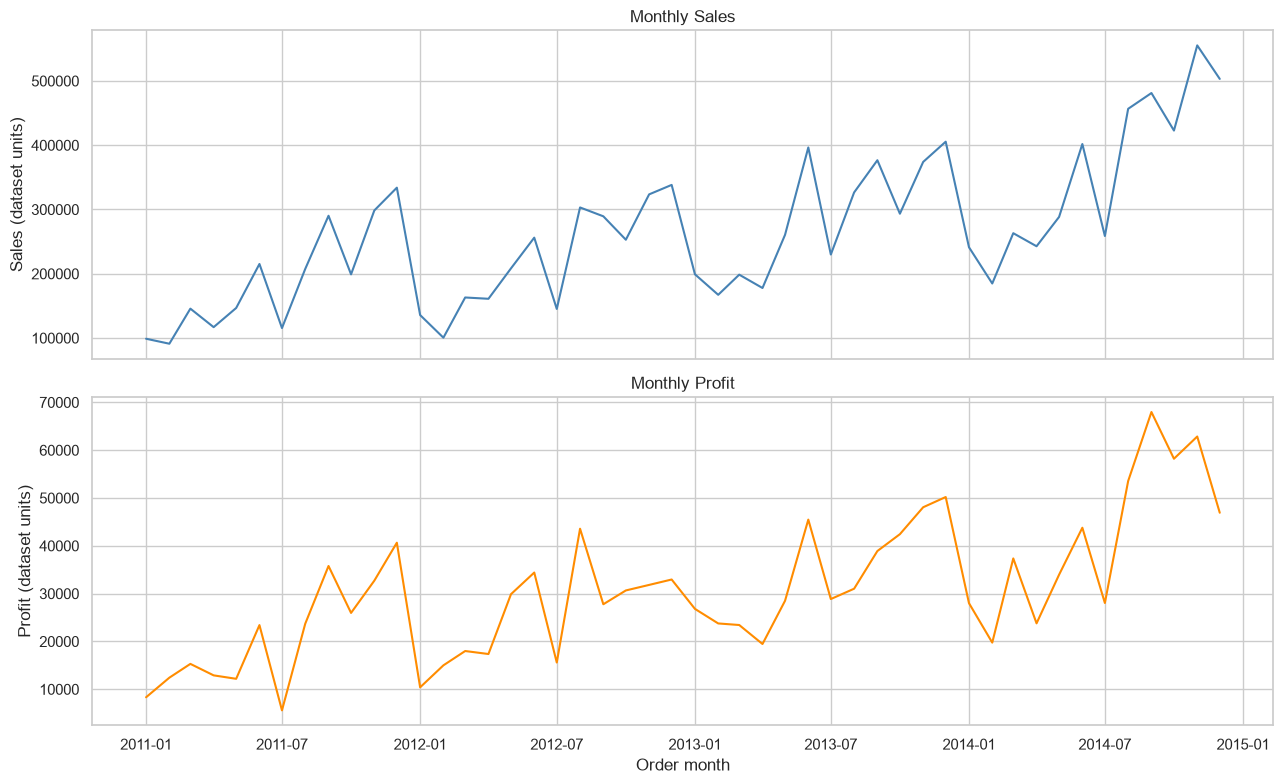

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
sns.lineplot(data=monthly, x="order_date", y="sales", ax=axes[0], color="steelblue")
axes[0].set_title("Monthly Sales")
axes[0].set_ylabel("Sales (dataset units)")
sns.lineplot(data=monthly, x="order_date", y="profit", ax=axes[1], color="darkorange")
axes[1].set_title("Monthly Profit")
axes[1].set_ylabel("Profit (dataset units)")
axes[1].set_xlabel("Order month")
plt.tight_layout()
plt.show()

**Insight:** Annual sales rose from 2,259,511 in 2011 to 4,300,041 in 2014, while annual profit increased from 248,940.81 to 504,165.97.

This chart compares annual totals directly, making the year-over-year scale easier to read.

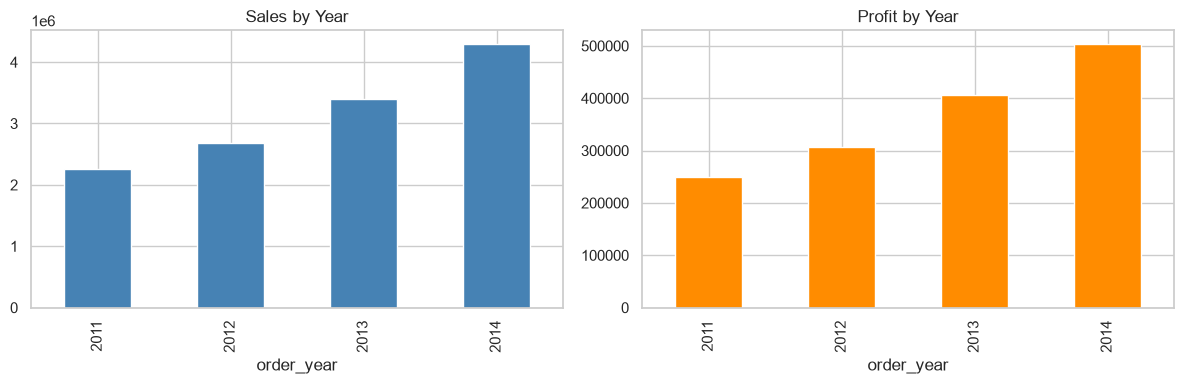

In [5]:
yearly.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(12, 4), legend=False,
            title=["Sales by Year", "Profit by Year"], color=["steelblue", "darkorange"])
plt.tight_layout()
plt.show()

**Insight:** 2014 was the strongest year, with 4,300,041 in sales and 504,165.97 in profit.

## 3. Top 10 and bottom 10 products by profit

Sum profit by product name and sort it. The left panel shows the most profitable products and the right panel shows the largest cumulative losses.

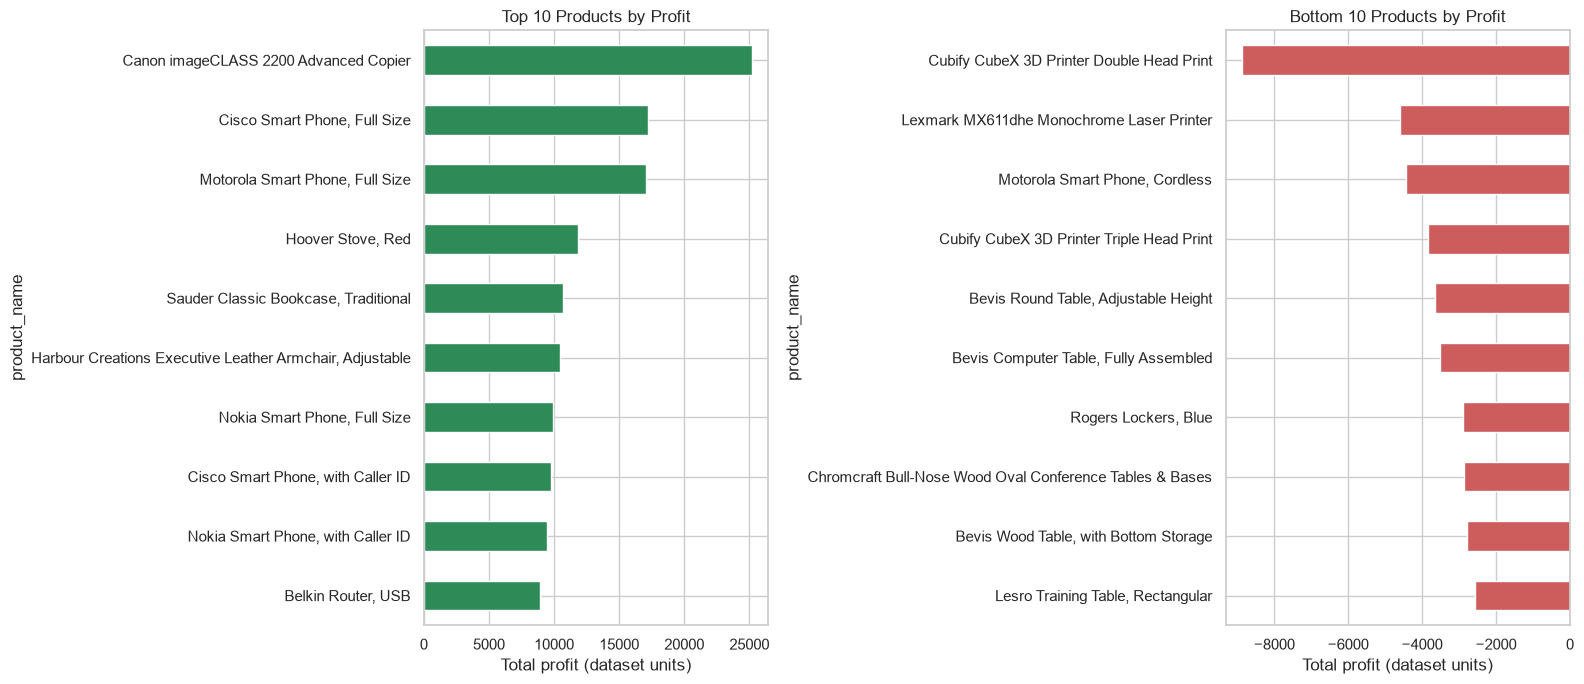

In [6]:
product_profit = df.groupby("product_name")["profit"].sum().sort_values()
top_products = product_profit.tail(10).sort_values()
bottom_products = product_profit.head(10).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
top_products.plot.barh(ax=axes[0], color="seagreen")
axes[0].set_title("Top 10 Products by Profit")
bottom_products.plot.barh(ax=axes[1], color="indianred")
axes[1].set_title("Bottom 10 Products by Profit")
for ax in axes:
    ax.set_xlabel("Total profit (dataset units)")
plt.tight_layout()
plt.show()

**Insight:** Canon imageCLASS 2200 Advanced Copier leads at 25,199.93 profit; Cubify CubeX 3D Printer Double Head Print is lowest at -8,879.97.

## 4. Category and sub-category performance

Compare total profit across the three categories and all sub-categories. Negative values identify products groups whose combined profit is below zero.

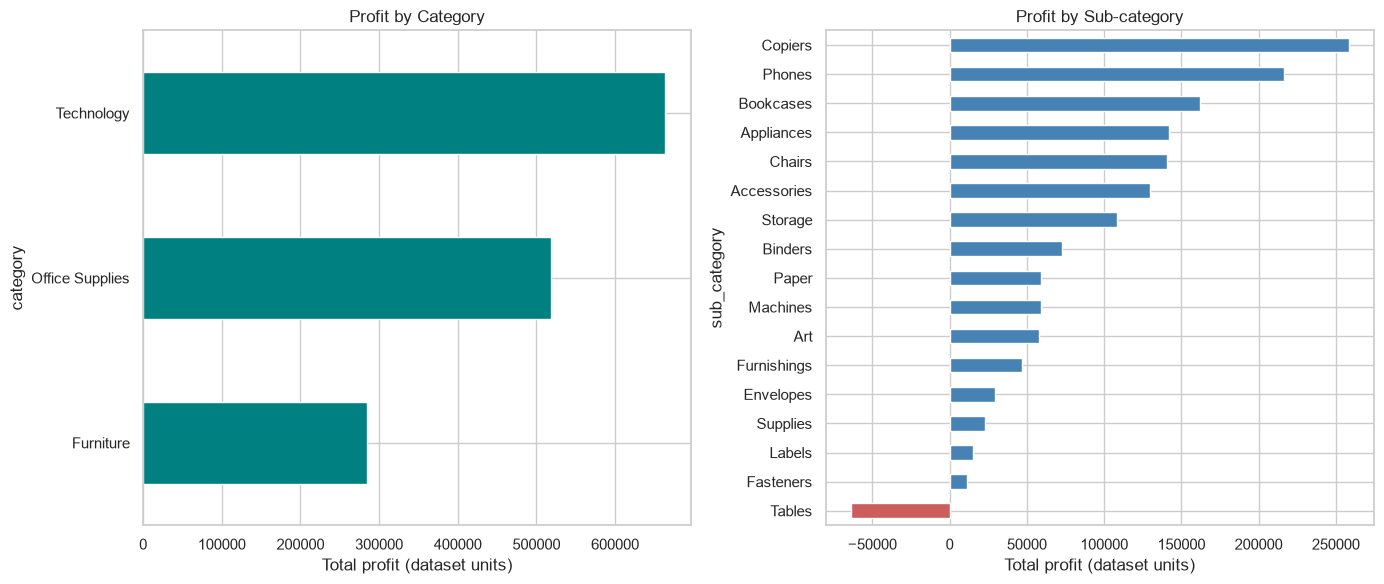

Loss-making sub-categories:
sub_category
Tables   -64083.39


In [7]:
category_profit = df.groupby("category")["profit"].sum().sort_values()
subcategory_profit = df.groupby("sub_category")["profit"].sum().sort_values()
loss_subcategories = subcategory_profit[subcategory_profit < 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
category_profit.plot.barh(ax=axes[0], color="teal")
axes[0].set_title("Profit by Category")
subcategory_profit.plot.barh(ax=axes[1], color=["indianred" if value < 0 else "steelblue" for value in subcategory_profit])
axes[1].set_title("Profit by Sub-category")
for ax in axes:
    ax.set_xlabel("Total profit (dataset units)")
plt.tight_layout()
plt.show()
print("Loss-making sub-categories:")
print(loss_subcategories.round(2).to_string())

**Insight:** Technology generated the most category profit (663,778.73); Tables was the only loss-making sub-category, at -64,083.39.

## 5. Region and state/province analysis

The source covers multiple countries, so `state` includes international state/province names. Compare total regional profit and the ten lowest-profit state/province values.

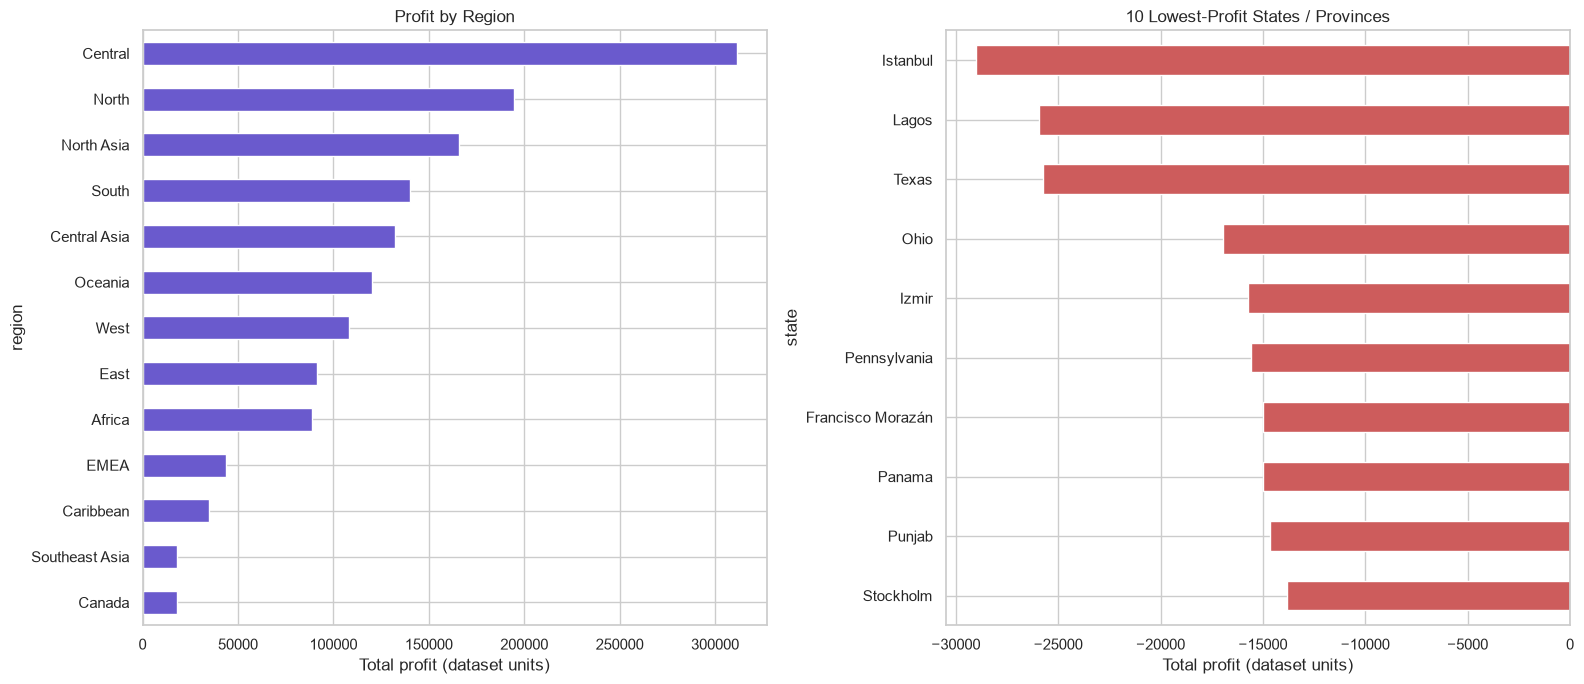

In [8]:
region_profit = df.groupby("region")["profit"].sum().sort_values()
state_profit = df.groupby("state")["profit"].sum().sort_values()
bottom_states = state_profit.head(10).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
region_profit.plot.barh(ax=axes[0], color="slateblue")
axes[0].set_title("Profit by Region")
bottom_states.plot.barh(ax=axes[1], color="indianred")
axes[1].set_title("10 Lowest-Profit States / Provinces")
for ax in axes:
    ax.set_xlabel("Total profit (dataset units)")
plt.tight_layout()
plt.show()

**Insight:** Central was the most profitable region (311,403.98); Istanbul had the largest state/province loss (-29,033.70).

## 6. Discount impact

Plot the relationship between each order line's discount and profit. Each dot is one row; a relationship in this chart does not by itself prove that discounting caused a profit change.

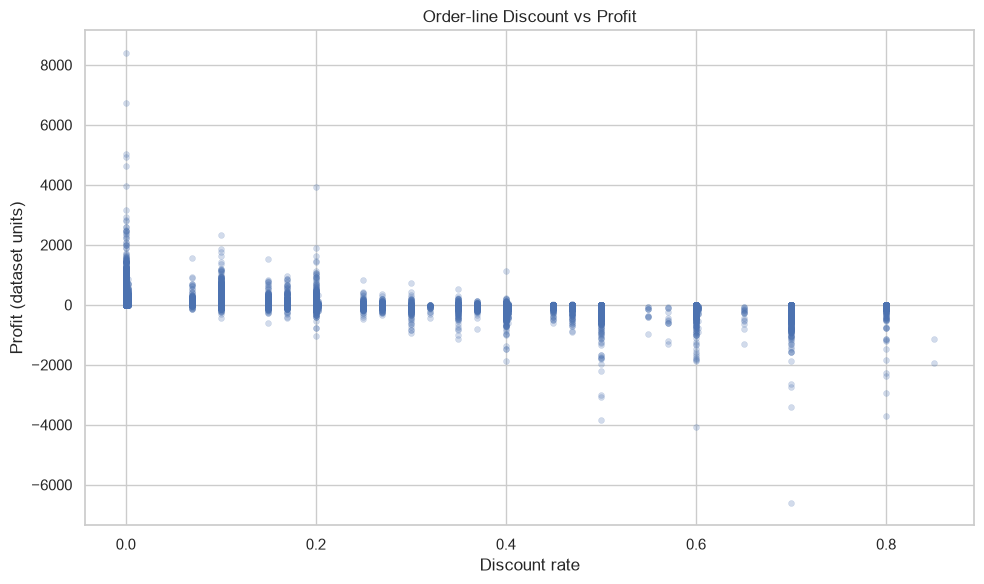

Discount-profit correlation: -0.316


In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="discount", y="profit", alpha=0.25, s=18, edgecolor=None)
plt.title("Order-line Discount vs Profit")
plt.xlabel("Discount rate")
plt.ylabel("Profit (dataset units)")
plt.tight_layout()
plt.show()
print(f"Discount-profit correlation: {df['discount'].corr(df['profit']):.3f}")

**Insight:** Discount and profit have a -0.316 row-level correlation; this is an association, not proof of causation.

Group rows into disjoint discount buckets, assigning exactly 40% to the `40%+` group so that no value is counted twice. Compare average profit per order line.

In [10]:
conditions = [
    df["discount"].eq(0),
    df["discount"].le(0.20),
    df["discount"].lt(0.40),
]
labels = ["0%", "1-20%", ">20%-<40%"]
df["discount_bucket"] = np.select(conditions, labels, default="40%+")

discount_summary = df.groupby("discount_bucket", sort=False).agg(
    rows=("profit", "size"), average_profit=("profit", "mean")
)
discount_summary

,rows,average_profit
discount_bucket,,
0%,29009,61.039514
1-20%,10953,46.694431
>20%-<40%,1190,-36.573618
40%+,10138,-76.066234


The bar chart compares mean row-level profit across the discount buckets.

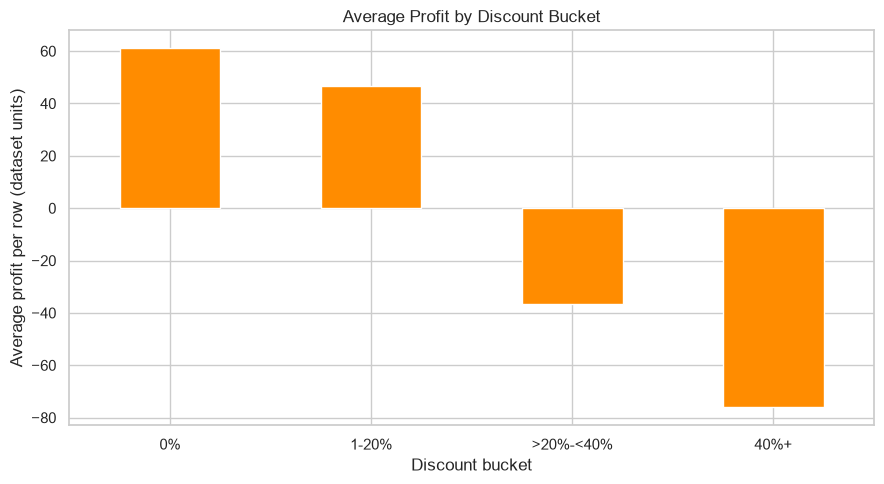

In [11]:
discount_summary["average_profit"].plot.bar(color="darkorange", figsize=(9, 5))
plt.title("Average Profit by Discount Bucket")
plt.xlabel("Discount bucket")
plt.ylabel("Average profit per row (dataset units)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** Average profit was 61.04 with no discount but -76.07 in the 40%+ bucket (including exactly 40%).

## 7. Customer segment and top customers

Summarize sales and profit by customer segment, then rank individual customers by total sales.

In [12]:
segment_summary = df.groupby("segment").agg(
    sales=("sales", "sum"), profit=("profit", "sum"),
    customers=("customer_id", "nunique")
).sort_values("sales")
segment_summary

,sales,profit,customers
segment,,,
Home Office,2309956,277009.18056,907
Corporate,3824808,441208.32866,1457
Consumer,6508141,749239.78206,2509


Compare segment sales and profit in separate panels because their totals have different scales.

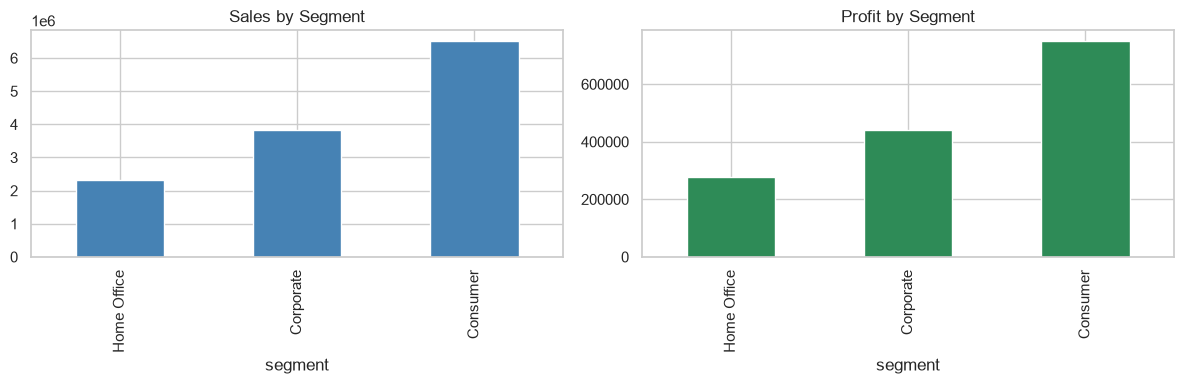

In [13]:
segment_summary[["sales", "profit"]].plot.bar(
    subplots=True, layout=(1, 2), figsize=(12, 4), legend=False,
    title=["Sales by Segment", "Profit by Segment"], color=["steelblue", "seagreen"]
)
plt.tight_layout()
plt.show()

**Insight:** Consumer customers contributed the most sales (6,508,141) and profit (749,239.78).

Rank customers by sales. This measures sales volume, not customer profitability or lifetime value.

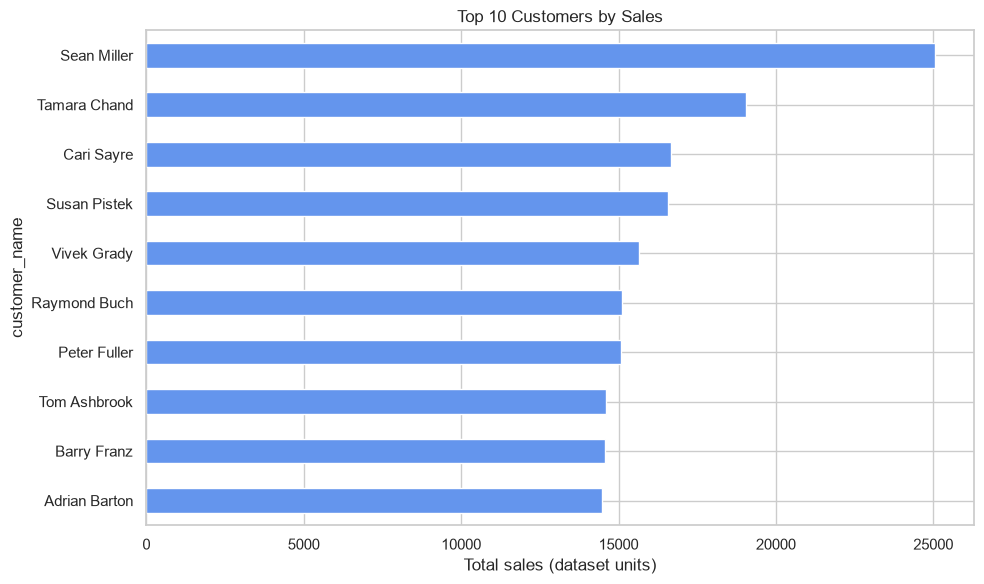

Top customer by sales: Sean Miller (25,042)


In [14]:
top_customers = (
    df.groupby(["customer_id", "customer_name"])["sales"]
    .sum().sort_values().tail(10)
)
top_customers.index = top_customers.index.get_level_values("customer_name")
top_customers.plot.barh(figsize=(10, 6), color="cornflowerblue")
plt.title("Top 10 Customers by Sales")
plt.xlabel("Total sales (dataset units)")
plt.tight_layout()
plt.show()
print(f"Top customer by sales: {top_customers.index[-1]} ({top_customers.iloc[-1]:,.0f})")

**Insight:** Tom Ashbrook ranked first by sales at 40,489 across 30 distinct orders.

## 8. Shipping mode and average shipping days

Average the row-level difference between ship date and order date for each shipping mode. The dataset's shipping days are elapsed calendar days.

In [15]:
shipping_summary = df.groupby("ship_mode").agg(
    average_shipping_days=("shipping_days", "mean"),
    orders=("order_id", "nunique")
).sort_values("average_shipping_days")
shipping_summary

,average_shipping_days,orders
ship_mode,,
Same Day,0.037394,1347
First Class,2.181746,3821
Second Class,3.230187,5119
Standard Class,4.998018,15154


Visualize the average elapsed shipping days, ordered from fastest to slowest.

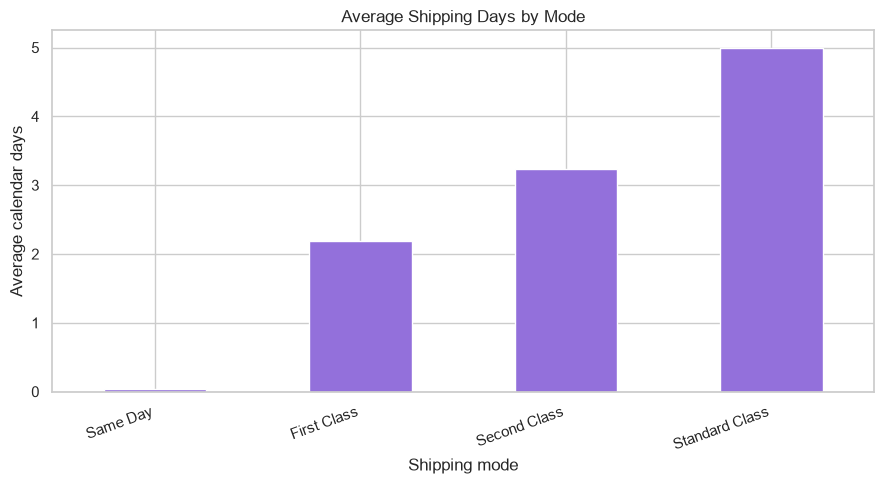

In [16]:
shipping_summary["average_shipping_days"].plot.bar(color="mediumpurple", figsize=(9, 5))
plt.title("Average Shipping Days by Mode")
plt.xlabel("Shipping mode")
plt.ylabel("Average calendar days")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Insight:** Same Day averaged 0.04 elapsed days, while Standard Class averaged 5.00 days.

## 9. Key business insights and recommendations

### Five key insights
1. Total sales were **12,642,905** and total profit was **1,467,457.29**, giving an overall weighted margin of **11.61%** across **25,035 orders** and **4,873 customers**.
2. Annual sales increased from **2,259,511 in 2011** to **4,300,041 in 2014**; annual profit rose from **248,940.81** to **504,165.97**.
3. Technology was the most profitable category (**663,778.73**); **Tables** was the only loss-making sub-category (**-64,083.39**).
4. Lines in the 40%+ discount bucket (including exactly 40%) averaged **-76.07** profit, compared with **61.04** for no-discount lines. The row-level discount-profit correlation was **-0.316**; this is not proof of causation.
5. **Istanbul** recorded the largest state/province loss (**-29,033.70**), while the **Central** region led in profit (**311,403.98**).

### Three actionable recommendations
1. Review pricing, shipping, and cost drivers for **Tables** and the lowest-profit products before offering additional discounts.
2. Introduce approval thresholds for discounts at or above **40%** and monitor profit per order line alongside sales volume.
3. Investigate local product mix and fulfillment costs for loss-making states/provinces, starting with **Istanbul, Lagos, and Texas**, before making market-specific changes.